<a href="https://colab.research.google.com/github/2403a54081-arch/UnitTest/blob/main/Copy_of_Deep_Learning_for_Traffic_Flow_Prediction_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

PyTorch Version: 2.11.0+cu130
GPU Available: Tesla T4


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
!pip install torch pandas numpy matplotlib seaborn scikit-learn tables h5py

In [ ]:
import os
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
DATASET_NAME = "pems-bay"

if DATASET_NAME == "pems-bay":
    FILE_PATH = "/content/pems-bay.h5"

elif DATASET_NAME == "metr-la":
    FILE_PATH = "/content/metr-la.h5"

else:
    raise ValueError("Invalid dataset name")

print("Selected Dataset:", DATASET_NAME)
print("File Path:", FILE_PATH)

assert os.path.exists(FILE_PATH), "Dataset file not found!"

Selected Dataset: pems-bay
File Path: /content/pems-bay.h5


In [ ]:
df = pd.read_hdf(FILE_PATH)

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

print("\nFirst five rows:")

print(df.head())

Dataset loaded successfully!
Dataset shape: (52116, 325)

First five rows:
sensor_id            400001  400017  400030  400040  400045  400052  400057  \
2017-01-01 00:00:00    71.4    67.8    70.5    67.4    68.8    66.6    66.8   
2017-01-01 00:05:00    71.6    67.5    70.6    67.5    68.7    66.6    66.8   
2017-01-01 00:10:00    71.6    67.6    70.2    67.4    68.7    66.1    66.8   
2017-01-01 00:15:00    71.1    67.5    70.3    68.0    68.5    66.7    66.6   
2017-01-01 00:20:00    71.7    67.8    70.2    68.1    68.4    66.9    66.1   

sensor_id            400059  400065  400069  ...  409525  409526  409528  \
2017-01-01 00:00:00    68.0    66.8    69.0  ...    68.8    67.9    68.8   
2017-01-01 00:05:00    67.8    66.5    68.2  ...    68.4    67.3    68.4   
2017-01-01 00:10:00    67.8    66.2    67.8  ...    68.4    67.4    68.4   
2017-01-01 00:15:00    67.7    65.9    67.8  ...    68.5    67.5    68.5   
2017-01-01 00:20:00    67.7    66.1    67.8  ...    68.5    67.7    68

In [ ]:
print("Dataset Information")

print("Number of time steps:", df.shape[0])

print("Number of sensors:", df.shape[1])

print("\nMissing Values:")

print(df.isnull().sum().sum())

print("\nStatistical Description:")

print(df.describe())

Dataset Information
Number of time steps: 52116
Number of sensors: 325

Missing Values:
0

Statistical Description:
sensor_id        400001        400017        400030        400040  \
count      52116.000000  52116.000000  52116.000000  52116.000000   
mean          67.568557     59.019079     59.138577     62.137407   
std            8.119154     13.250178     11.658612      8.617881   
min            0.000000     11.000000      3.400000      0.000000   
25%           67.300000     62.200000     55.800000     59.400000   
50%           70.300000     64.000000     62.700000     66.200000   
75%           71.300000     65.100000     66.600000     67.700000   
max           80.400000     71.600000     77.700000     76.900000   

sensor_id        400045        400052        400057        400059  \
count      52116.000000  52116.000000  52116.000000  52116.000000   
mean          61.195873     63.314788     58.777483     63.565579   
std           11.019177     11.159615     13.078931    

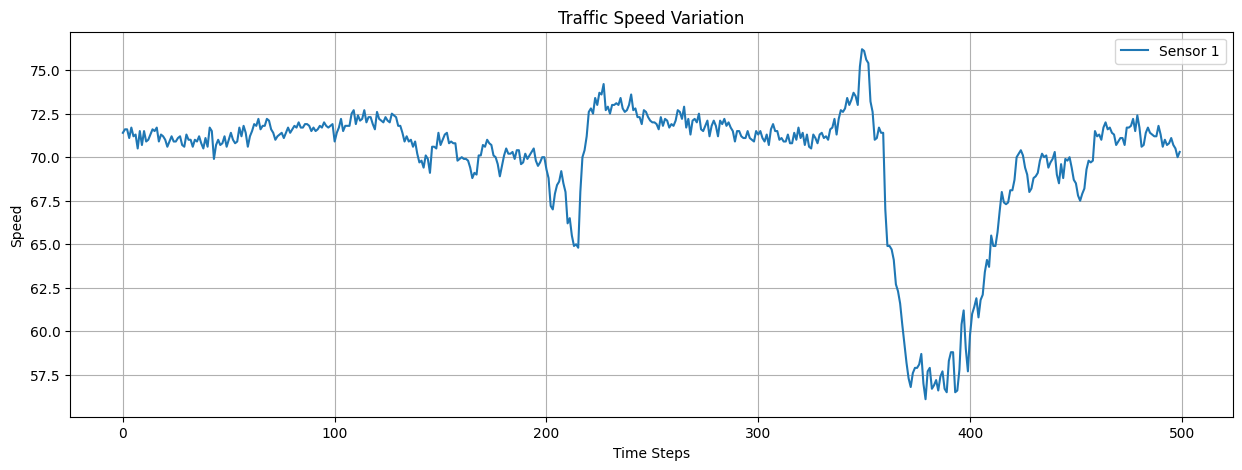

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    df.iloc[:500, 0].values,
    label="Sensor 1"
)

plt.title("Traffic Speed Variation")

plt.xlabel("Time Steps")

plt.ylabel("Speed")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# Convert data into numerical format

df = df.apply(pd.to_numeric, errors="coerce")

# Replace infinite values

df = df.replace([np.inf, -np.inf], np.nan)

# Fill missing values using interpolation

df = df.interpolate(
    method="linear",
    axis=0,
    limit_direction="both"
)

# Fill any remaining missing values

df = df.ffill().bfill()

print("Missing values after preprocessing:",
      df.isnull().sum().sum())

print("Preprocessing completed!")

Missing values after preprocessing: 0
Preprocessing completed!


In [ ]:
data = df.to_numpy(dtype=np.float32)

print("Data shape:", data.shape)

print("Number of sensors:", data.shape[1])

print("Number of observations:", data.shape[0])

Data shape: (52116, 325)
Number of sensors: 325
Number of observations: 52116


In [ ]:
total_length = len(data)

train_end = int(total_length * 0.70)

val_end = int(total_length * 0.80)

train_data = data[:train_end]

val_data = data[train_end:val_end]

test_data = data[val_end:]

print("Training data:", train_data.shape)

print("Validation data:", val_data.shape)

print("Testing data:", test_data.shape)

Training data: (36481, 325)
Validation data: (5211, 325)
Testing data: (10424, 325)


In [ ]:
mean = train_data.mean(axis=0)

std = train_data.std(axis=0)

std[std < 1e-6] = 1.0

train_scaled = (train_data - mean) / std

val_scaled = (val_data - mean) / std

test_scaled = (test_data - mean) / std

print("Normalization completed!")

print("Training mean:", train_scaled.mean())

print("Training standard deviation:",
      train_scaled.std())

Normalization completed!
Training mean: -1.4430589e-06
Training standard deviation: 1.0000011


In [ ]:
# Calculate correlation between sensors
correlation = np.corrcoef(
    train_scaled,
    rowvar=False
)

correlation = np.nan_to_num(
    correlation,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Use absolute correlation as edge strength
correlation = np.abs(correlation)

# Remove self-connections
np.fill_diagonal(correlation, 0)

# Number of neighboring sensors
K_NEIGHBORS = 5

num_sensors = correlation.shape[0]

adjacency = np.zeros_like(correlation)

for i in range(num_sensors):

    top_k = np.argsort(
        correlation[i]
    )[-K_NEIGHBORS:]

    adjacency[i, top_k] = correlation[i, top_k]

print("Adjacency Matrix Shape:", adjacency.shape)

print("Graph construction completed!")

Adjacency Matrix Shape: (325, 325)
Graph construction completed!


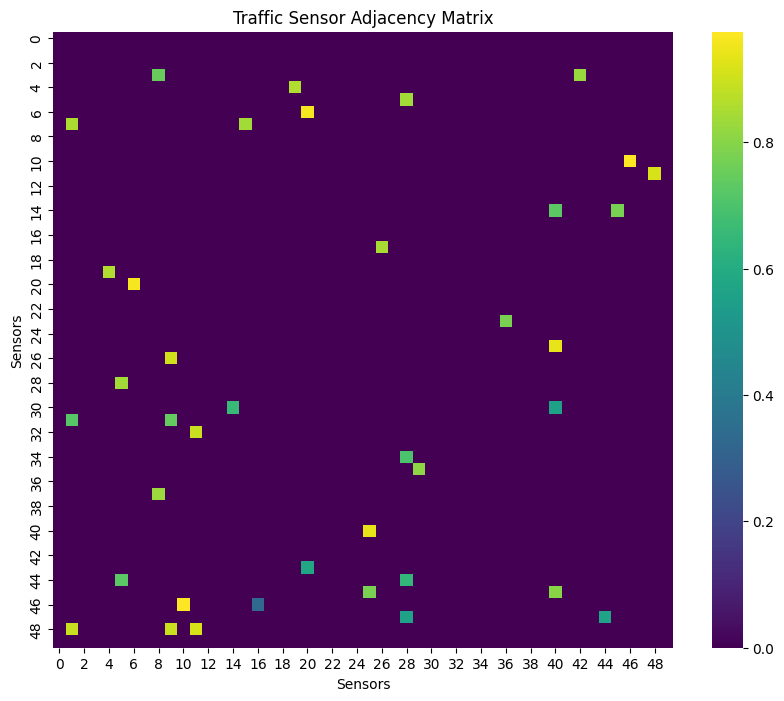

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    adjacency[:50, :50],
    cmap="viridis"
)

plt.title("Traffic Sensor Adjacency Matrix")

plt.xlabel("Sensors")

plt.ylabel("Sensors")

plt.show()

In [ ]:
def normalize_adjacency(A):

    row_sum = A.sum(axis=1)

    row_sum[row_sum == 0] = 1

    return A / row_sum[:, None]


A_forward = normalize_adjacency(adjacency)

A_reverse = normalize_adjacency(adjacency.T)

print("Forward matrix:", A_forward.shape)

print("Reverse matrix:", A_reverse.shape)

Forward matrix: (325, 325)
Reverse matrix: (325, 325)


In [ ]:
INPUT_LENGTH = 12

PRED_LENGTH = 12

BATCH_SIZE = 32

print("Input time steps:", INPUT_LENGTH)

print("Prediction time steps:", PRED_LENGTH)

Input time steps: 12
Prediction time steps: 12


In [ ]:
class TrafficDataset(Dataset):

    def __init__(
        self,
        data,
        input_length=12,
        pred_length=12
    ):

        self.data = torch.tensor(
            data,
            dtype=torch.float32
        )

        self.input_length = input_length

        self.pred_length = pred_length

    def __len__(self):

        return (
            len(self.data)
            - self.input_length
            - self.pred_length
            + 1
        )

    def __getitem__(self, index):

        x = self.data[
            index:index + self.input_length
        ]

        y = self.data[
            index + self.input_length:
            index + self.input_length + self.pred_length
        ]

        # Add feature dimension

        x = x.unsqueeze(-1)

        y = y.unsqueeze(-1)

        return x, y

In [ ]:
train_dataset = TrafficDataset(
    train_scaled,
    INPUT_LENGTH,
    PRED_LENGTH
)

val_dataset = TrafficDataset(
    val_scaled,
    INPUT_LENGTH,
    PRED_LENGTH
)

test_dataset = TrafficDataset(
    test_scaled,
    INPUT_LENGTH,
    PRED_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))

print("Validation samples:", len(val_dataset))

print("Testing samples:", len(test_dataset))

Training samples: 36458
Validation samples: 5188
Testing samples: 10401


In [ ]:
x_sample, y_sample = next(
    iter(train_loader)
)

print("Input shape:", x_sample.shape)

print("Target shape:", y_sample.shape)

Input shape: torch.Size([32, 12, 325, 1])
Target shape: torch.Size([32, 12, 325, 1])


In [ ]:
class DiffusionConv(nn.Module):

    def __init__(
        self,
        input_channels,
        output_channels,
        supports,
        diffusion_steps=2
    ):

        super().__init__()

        self.supports = supports

        self.diffusion_steps = diffusion_steps

        total_channels = input_channels * (
            1 + len(supports) * diffusion_steps
        )

        self.linear = nn.Linear(
            total_channels,
            output_channels
        )

    def forward(self, x):

        features = [x]

        for support in self.supports:

            x_k = x

            for k in range(self.diffusion_steps):

                x_k = torch.einsum(
                    "nm,bmc->bnc",
                    support,
                    x_k
                )

                features.append(x_k)

        result = torch.cat(
            features,
            dim=-1
        )

        return self.linear(result)

In [ ]:
class DCGRUCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, supports, diffusion_steps=2):
        super().__init__()
        self.hidden_dim = hidden_dim
        # Gate conv produces both update gate r and reset gate u (2 * hidden_dim channels)
        self.gate_conv = DiffusionConv(
            input_channels=input_dim + hidden_dim,
            output_channels=2 * hidden_dim,
            supports=supports,
            diffusion_steps=diffusion_steps
        )
        # Candidate state conv produces the candidate hidden state h_tilde
        self.candidate_conv = DiffusionConv(
            input_channels=input_dim + hidden_dim,
            output_channels=hidden_dim,
            supports=supports,
            diffusion_steps=diffusion_steps
        )

    def forward(self, x, h):
        # x shape: [batch_size, num_nodes, input_dim]
        # h shape: [batch_size, num_nodes, hidden_dim]
        combined = torch.cat([x, h], dim=-1)

        # Compute reset gate r and update gate u
        gates = torch.sigmoid(self.gate_conv(combined))
        r, u = torch.split(gates, self.hidden_dim, dim=-1)

        # Compute candidate state
        combined_candidate = torch.cat([x, r * h], dim=-1)
        h_tilde = torch.tanh(self.candidate_conv(combined_candidate))

        # Next hidden state
        next_h = u * h + (1.0 - u) * h_tilde
        return next_h

In [ ]:
class DCRNN(nn.Module):

    def __init__(
        self,
        num_nodes,
        input_dim,
        hidden_dim,
        output_dim,
        supports,
        pred_length,
        diffusion_steps=2
    ):

        super().__init__()

        self.num_nodes = num_nodes

        self.hidden_dim = hidden_dim

        self.pred_length = pred_length

        self.cell = DCGRUCell(
            input_dim,
            hidden_dim,
            supports,
            diffusion_steps
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            output_dim
        )

    def forward(
        self,
        x,
        target=None,
        teacher_forcing_ratio=0.0
    ):

        batch_size = x.shape[0]

        device = x.device

        h = torch.zeros(
            batch_size,
            self.num_nodes,
            self.hidden_dim,
            device=device
        )

        # Encoder

        for t in range(x.shape[1]):

            h = self.cell(
                x[:, t],
                h
            )

        # Decoder

        decoder_input = x[:, -1]

        predictions = []

        for t in range(self.pred_length):

            h = self.cell(
                decoder_input,
                h
            )

            output = self.output_layer(h)

            predictions.append(output)

            if (
                target is not None
                and random.random() < teacher_forcing_ratio
            ):

                decoder_input = target[:, t]

            else:

                decoder_input = output

        return torch.stack(
            predictions,
            dim=1
        )

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

supports = [
    torch.tensor(
        A_forward,
        dtype=torch.float32,
        device=device
    ),

    torch.tensor(
        A_reverse,
        dtype=torch.float32,
        device=device
    )
]

NUM_NODES = data.shape[1]

INPUT_DIM = 1

HIDDEN_DIM = 32

OUTPUT_DIM = 1

model = DCRNN(
    num_nodes=NUM_NODES,
    input_dim=INPUT_DIM,
    hidden_dim=HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    supports=supports,
    pred_length=PRED_LENGTH,
    diffusion_steps=1
).to(device)

print(model)

Using device: cuda
DCRNN(
  (cell): DCGRUCell(
    (gate_conv): DiffusionConv(
      (linear): Linear(in_features=99, out_features=64, bias=True)
    )
    (candidate_conv): DiffusionConv(
      (linear): Linear(in_features=99, out_features=32, bias=True)
    )
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)


In [ ]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)

print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
def train_one_epoch(model, loader):

    model.train()

    total_loss = 0

    for x, y in loader:

        x = x.to(device)

        y = y.to(device)

        optimizer.zero_grad()

        predictions = model(
            x,
            target=y,
            teacher_forcing_ratio=0.5
        )

        loss = criterion(
            predictions,
            y
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [ ]:
def validate(model, loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device)

            y = y.to(device)

            predictions = model(x)

            loss = criterion(
                predictions,
                y
            )

            total_loss += loss.item()

    return total_loss / len(loader)

In [ ]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU Available: True
GPU: Tesla T4


In [ ]:
# Use a smaller dataset for faster training

data = data[:10000]

total_length = len(data)

train_end = int(total_length * 0.70)
val_end = int(total_length * 0.80)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

Training: (7000, 325)
Validation: (1000, 325)
Testing: (2000, 325)


In [ ]:
# Use a smaller dataset for faster training

data = data[:10000]

total_length = len(data)

train_end = int(total_length * 0.70)
val_end = int(total_length * 0.80)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

Training: (7000, 325)
Validation: (1000, 325)
Testing: (2000, 325)


In [ ]:
EPOCHS = 5

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader
    )

    val_loss = validate(
        model,
        val_loader
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}",
        flush=True
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

if best_model_state is not None:

    model.load_state_dict(best_model_state)

    torch.save(
        model.state_dict(),
        "/content/best_dcrnn_model.pth"
    )

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)

Epoch [1/5] Train Loss: 0.9928 Val Loss: 1.3281
Epoch [2/5] Train Loss: 0.9924 Val Loss: 1.3281
Epoch [3/5] Train Loss: 0.9926 Val Loss: 1.3281
Epoch [4/5] Train Loss: 0.9928 Val Loss: 1.3281
Epoch [5/5] Train Loss: 0.9929 Val Loss: 1.3281

Training completed!
Best validation loss: 1.3280895915499493


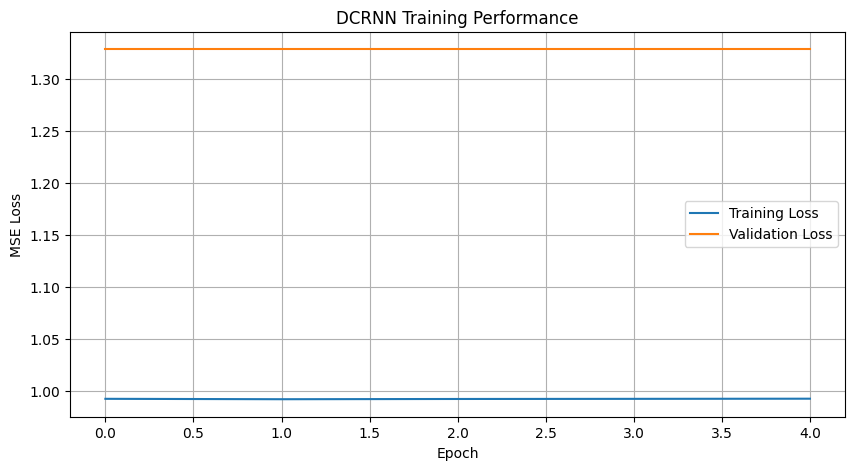

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.title("DCRNN Training Performance")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
model.eval()

all_predictions = []

all_actuals = []

with torch.no_grad():

    for x, y in test_loader:

        x = x.to(device)

        predictions = model(x)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_actuals.append(
            y.numpy()
        )

predictions = np.concatenate(
    all_predictions,
    axis=0
)

actuals = np.concatenate(
    all_actuals,
    axis=0
)

print("Predictions shape:", predictions.shape)

print("Actual values shape:", actuals.shape)

Predictions shape: (10401, 12, 325, 1)
Actual values shape: (10401, 12, 325, 1)


In [ ]:
predictions_original = (
    predictions[..., 0] * std[None, None, :]
    + mean[None, None, :]
)

actuals_original = (
    actuals[..., 0] * std[None, None, :]
    + mean[None, None, :]
)

print("Original-scale predictions generated!")

Original-scale predictions generated!


In [ ]:
y_true = actuals_original.flatten()

y_pred = predictions_original.flatten()

mae = mean_absolute_error(
    y_true,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

mask = np.abs(y_true) > 1.0

mape = np.mean(
    np.abs(
        (y_true[mask] - y_pred[mask])
        / y_true[mask]
    )
) * 100

print("DCRNN MODEL PERFORMANCE")

print("-------------------------")

print(f"MAE  : {mae:.4f}")

print(f"RMSE : {rmse:.4f}")

print(f"MAPE : {mape:.2f}%")

DCRNN MODEL PERFORMANCE
-------------------------
MAE  : 5.8107
RMSE : 9.3136
MAPE : 14.26%


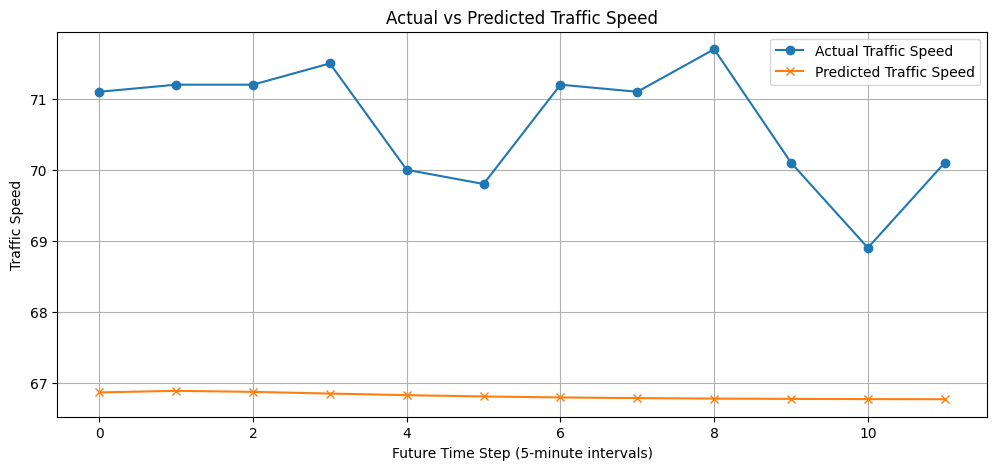

In [ ]:
sensor_id = 0

time_steps = np.arange(PRED_LENGTH)

plt.figure(figsize=(12, 5))

plt.plot(
    time_steps,
    actuals_original[0, :, sensor_id],
    marker="o",
    label="Actual Traffic Speed"
)

plt.plot(
    time_steps,
    predictions_original[0, :, sensor_id],
    marker="x",
    label="Predicted Traffic Speed"
)

plt.title(
    "Actual vs Predicted Traffic Speed"
)

plt.xlabel("Future Time Step (5-minute intervals)")

plt.ylabel("Traffic Speed")

plt.legend()

plt.grid(True)

plt.show()

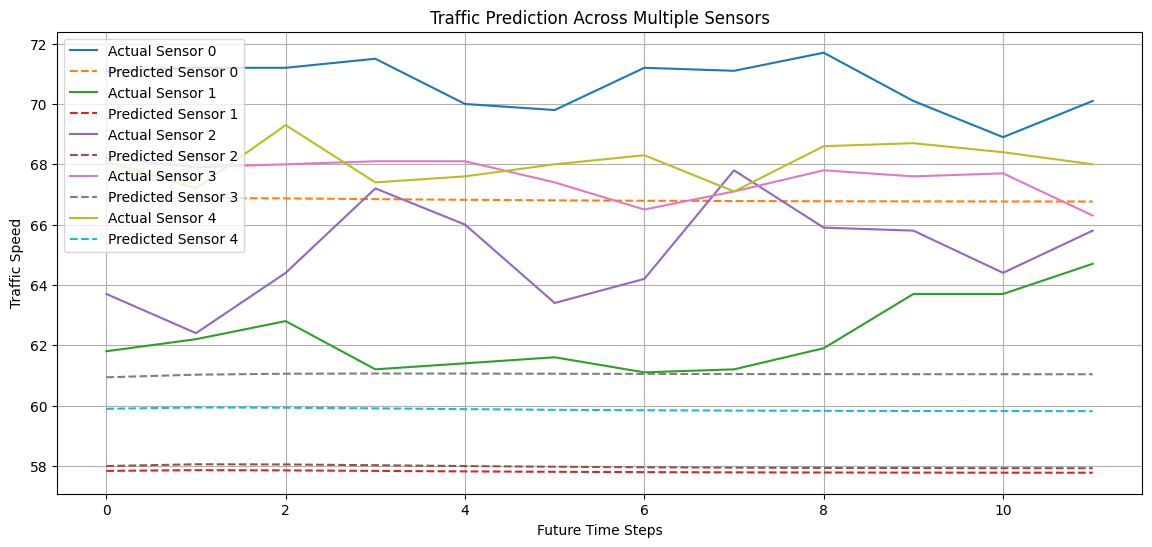

In [ ]:
plt.figure(figsize=(14, 6))

for sensor_id in range(
    min(5, NUM_NODES)
):

    plt.plot(
        actuals_original[0, :, sensor_id],
        label=f"Actual Sensor {sensor_id}"
    )

    plt.plot(
        predictions_original[0, :, sensor_id],
        linestyle="--",
        label=f"Predicted Sensor {sensor_id}"
    )

plt.title("Traffic Prediction Across Multiple Sensors")

plt.xlabel("Future Time Steps")

plt.ylabel("Traffic Speed")

plt.legend()

plt.grid(True)

plt.show()

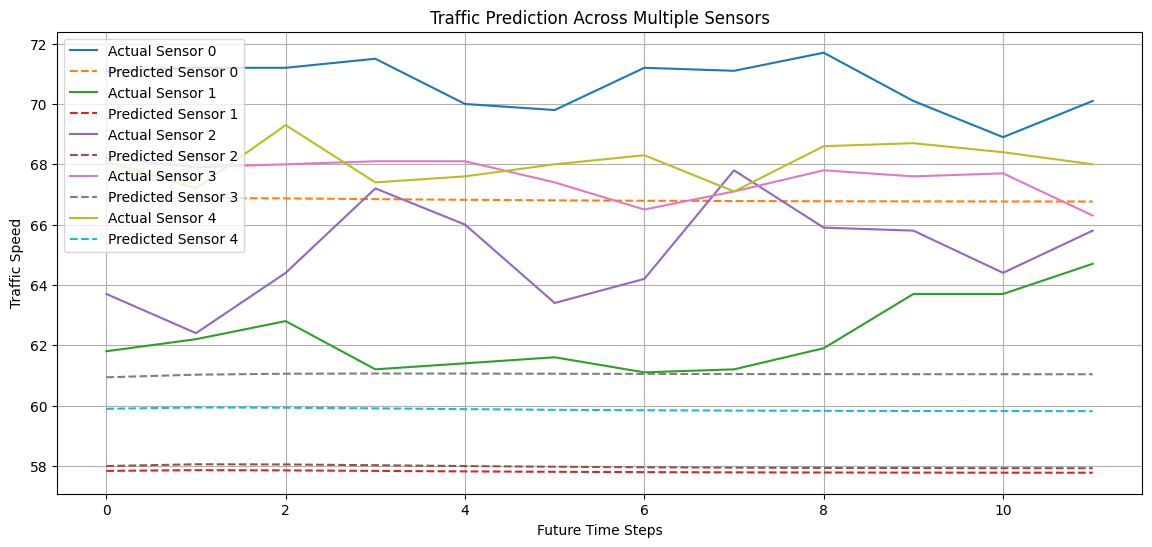

In [ ]:
plt.figure(figsize=(14, 6))

for sensor_id in range(
    min(5, NUM_NODES)
):

    plt.plot(
        actuals_original[0, :, sensor_id],
        label=f"Actual Sensor {sensor_id}"
    )

    plt.plot(
        predictions_original[0, :, sensor_id],
        linestyle="--",
        label=f"Predicted Sensor {sensor_id}"
    )

plt.title("Traffic Prediction Across Multiple Sensors")

plt.xlabel("Future Time Steps")

plt.ylabel("Traffic Speed")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# Persistence baseline:
# Repeat the latest observed speed for all future steps.

baseline = np.repeat(
    test_scaled[
        INPUT_LENGTH - 1:
        INPUT_LENGTH - 1 + len(test_dataset),
        :
    ][:, None, :],
    PRED_LENGTH,
    axis=1
)

baseline_original = (
    baseline * std[None, None, :]
    + mean[None, None, :]
)

baseline_mae = mean_absolute_error(
    actuals_original.flatten(),
    baseline_original.flatten()
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        actuals_original.flatten(),
        baseline_original.flatten()
    )
)

print("PERFORMANCE COMPARISON")

print("----------------------")

print("Persistence Baseline MAE:", baseline_mae)

print("DCRNN MAE:", mae)

print("Persistence Baseline RMSE:", baseline_rmse)

print("DCRNN RMSE:", rmse)

PERFORMANCE COMPARISON
----------------------
Persistence Baseline MAE: 2.1775448322296143
DCRNN MAE: 5.810739517211914
Persistence Baseline RMSE: 5.177721113477925
DCRNN RMSE: 9.313636659212351


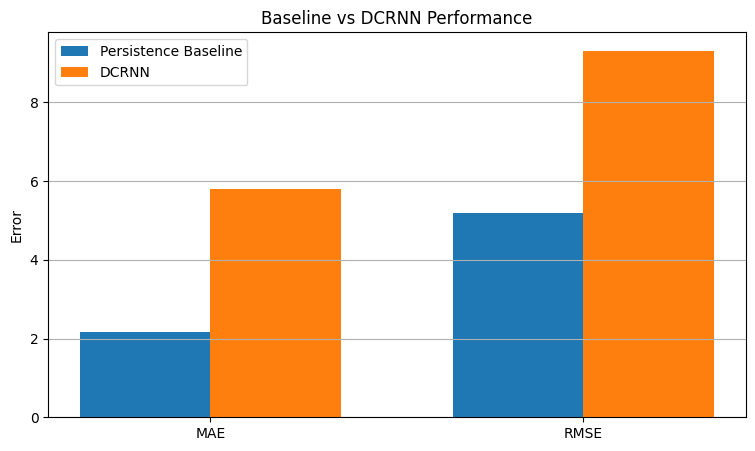

In [ ]:
metrics = ["MAE", "RMSE"]

baseline_scores = [
    baseline_mae,
    baseline_rmse
]

dcrnn_scores = [
    mae,
    rmse
]

x = np.arange(len(metrics))

width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    baseline_scores,
    width,
    label="Persistence Baseline"
)

plt.bar(
    x + width/2,
    dcrnn_scores,
    width,
    label="DCRNN"
)

plt.xticks(x, metrics)

plt.ylabel("Error")

plt.title("Baseline vs DCRNN Performance")

plt.legend()

plt.grid(axis="y")

plt.show()

In [ ]:
checkpoint = {
    "model_state_dict": model.state_dict(),

    "num_nodes": NUM_NODES,

    "input_length": INPUT_LENGTH,

    "pred_length": PRED_LENGTH,

    "hidden_dim": HIDDEN_DIM,

    "mean": mean,

    "std": std,

    "A_forward": A_forward,

    "A_reverse": A_reverse
}

torch.save(
    checkpoint,
    "/content/dcrnn_traffic_model.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download(
    "/content/dcrnn_traffic_model.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.eval()

latest_data = data[-INPUT_LENGTH:]

latest_scaled = (
    latest_data - mean
) / std

latest_tensor = torch.tensor(
    latest_scaled,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(-1)

latest_tensor = latest_tensor.to(device)

with torch.no_grad():

    future_prediction = model(
        latest_tensor
    )

future_prediction = (
    future_prediction
    .cpu()
    .numpy()[0, :, :, 0]
)

future_prediction = (
    future_prediction * std[None, :]
    + mean[None, :]
)

print("Future traffic prediction shape:",
      future_prediction.shape)

print("\nFirst 5 sensors – next 12 time steps:")

print(future_prediction[:, :5])

Future traffic prediction shape: (12, 325)

First 5 sensors – next 12 time steps:
[[66.86231  57.899727 57.987057 61.225456 59.959507]
 [66.874695 57.91041  58.00448  61.16108  59.94835 ]
 [66.8586   57.888554 57.99328  61.118347 59.918823]
 [66.83606  57.85993  57.97549  61.090042 59.88926 ]
 [66.81534  57.834126 57.95897  61.071304 59.865166]
 [66.79888  57.81385  57.945896 61.058918 59.84724 ]
 [66.78678  57.799034 57.936333 61.050747 59.83458 ]
 [66.778305 57.788696 57.92965  61.045383 59.82593 ]
 [66.77257  57.781708 57.925125 61.041885 59.820168]
 [66.76877  57.777096 57.92213  61.03962  59.816402]
 [66.76631  57.774113 57.92018  61.038166 59.813976]
 [66.76474  57.77221  57.918926 61.03724  59.812435]]


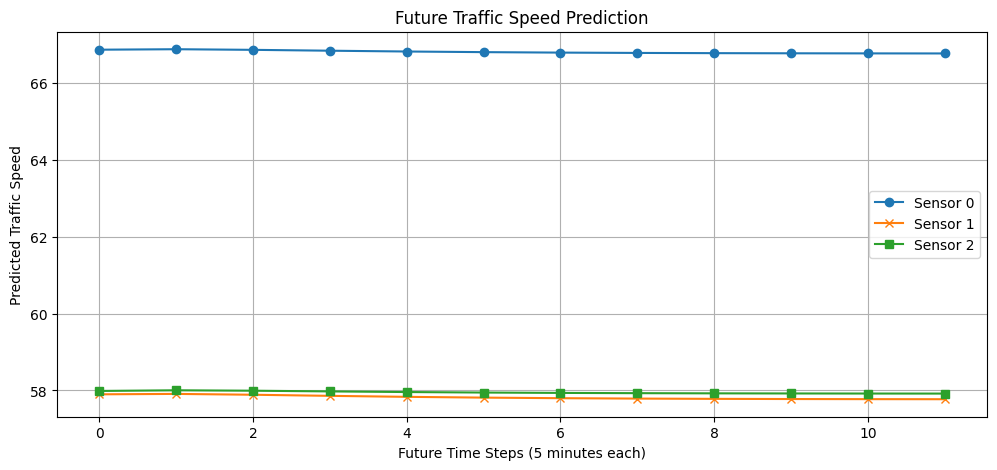

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    future_prediction[:, 0],
    marker="o",
    label="Sensor 0"
)

plt.plot(
    future_prediction[:, 1],
    marker="x",
    label="Sensor 1"
)

plt.plot(
    future_prediction[:, 2],
    marker="s",
    label="Sensor 2"
)

plt.title("Future Traffic Speed Prediction")

plt.xlabel("Future Time Steps (5 minutes each)")

plt.ylabel("Predicted Traffic Speed")

plt.legend()

plt.grid(True)

plt.show()